In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Rescaling
from tensorflow.keras.applications import MobileNetV2


In [10]:


# Load dataset
train = tf.keras.utils.image_dataset_from_directory(
    r"C:\Users\Vaishnavi\Downloads\cats_and_dogs_filtered\cats_and_dogs_filtered\train",
    image_size=(128,128),
    batch_size=32
)

validation = tf.keras.utils.image_dataset_from_directory(
    r"C:\Users\Vaishnavi\Downloads\cats_and_dogs_filtered\cats_and_dogs_filtered\validation",
    image_size=(128,128),
    batch_size=32
)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.


In [11]:
# Load MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128,128,3)
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [14]:

# Create model
from tensorflow.keras.layers import Rescaling
model = Sequential([
    Rescaling(1./127.5, offset=-1),
    base_model,
    GlobalAveragePooling2D(),
    Dense(64, activation="relu"),
    Dense(2, activation="softmax")
])

In [15]:
# Compile model
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:

# Train model
model.fit(train, epochs=5)

Epoch 1/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 64s 595ms/step - accuracy: 0.9555 - loss: 0.1182
Epoch 2/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 22s 295ms/step - accuracy: 0.9865 - loss: 0.0355
Epoch 3/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 17s 233ms/step - accuracy: 0.9965 - loss: 0.0159
Epoch 4/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 24s 294ms/step - accuracy: 0.9995 - loss: 0.0074
Epoch 5/5
63/63 ━━━━━━━━━━━━━━━━━━━━ 27s 398ms/step - accuracy: 1.0000 - loss: 0.0037


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 494ms/step
Actual: dogs
Predicted: dogs


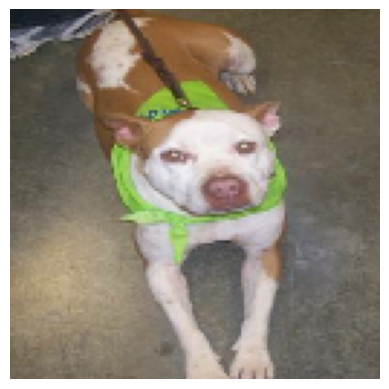

In [18]:
for x, y in validation.take(1):
    p = model.predict(x)

    print("Actual:", train.class_names[y[0]])
    print("Predicted:", train.class_names[np.argmax(p[0])])

    plt.imshow(x[0].numpy().astype("uint8"))
    plt.axis("off")
    plt.show()

In [ ]:
Q1. What is Transfer Learning?

Transfer Learning is a technique in which we use a previously trained model and apply its learned knowledge to solve a new problem. Instead of training a model from scratch, we reuse existing knowledge to save time and improve performance.

Q2. What is MobileNetV2?

MobileNetV2 is a lightweight Convolutional Neural Network (CNN) developed for image classification and feature extraction. It requires less computational power and is suitable for mobile and low-resource devices.

Q3. What is ImageNet?

ImageNet is a large image dataset containing millions of images belonging to thousands of categories. MobileNetV2 is pretrained on this dataset, so it has already learned useful image features.

Q4. Why do we use Transfer Learning instead of training a model from scratch?

We use Transfer Learning because it reduces training time, requires less data and uses previously learned features to improve classification performance.

Q5. What is the purpose of weights="imagenet"?

It loads the pretrained weights of MobileNetV2 that were learned from the ImageNet dataset.

Q6. What is the purpose of include_top=False?

It removes the original classification layer of MobileNetV2 so that we can add our own classification layers for cats and dogs.

Q7. Why do we use base_model.trainable = False?

It freezes the pretrained layers so their existing weights do not change during training. Only our newly added layers are trained.

Q8. What is the purpose of Rescaling(1./127.5, offset=-1)?

It converts pixel values from the range 0–255 into the range -1 to 1, which is the required input range for MobileNetV2.

Q9. What is GlobalAveragePooling2D?

It converts the feature maps produced by the convolutional layers into a single feature vector by calculating the average of each feature map.

Q10. Why do we use Dense layers?

Dense layers perform the final classification using the extracted features. In our model, the first Dense layer has 64 neurons and the final Dense layer has 2 neurons for cats and dogs.

Q11. What is the purpose of the ReLU activation function?

ReLU stands for Rectified Linear Unit. It introduces non-linearity into the model and helps it learn complex patterns.

Q12. Why do we use Softmax?

Softmax converts the model's output into probabilities for each class. The class with the highest probability is selected as the prediction.

Q13. What is an optimizer?

An optimizer updates the model's weights to minimize the loss during training. We use the Adam optimizer because it provides adaptive learning rates.

Q14. What is sparse categorical cross-entropy?

It is a loss function used for multi-class classification when class labels are represented as integer values instead of one-hot encoded vectors.

Q15. What is an epoch?

One epoch means the model has completed one full pass through the entire training dataset. In our implementation, we train the model for 5 epochs.

Q16. What is batch size?

Batch size is the number of images processed together before updating the model's weights. Here, our batch size is 32.

Q17. What is the difference between training and validation datasets?

The training dataset is used to teach the model, whereas the validation dataset is used to evaluate its performance on images that were not used for training.

Q18. What is CNN?

CNN stands for Convolutional Neural Network. It is a deep learning architecture mainly used for image processing and recognition.

Q19. What is fine-tuning?

Fine-tuning is a transfer learning technique in which we unfreeze some pretrained layers and train them further on our new dataset to improve performance.

Q20. How does our model predict whether an image contains a cat or dog?

First, MobileNetV2 extracts important image features. These features are passed through Global Average Pooling and Dense layers. The final Softmax layer produces probabilities for both classes, and argmax() selects the class with the highest probability.

Q21. What is the purpose of model.evaluate()?

It evaluates the trained model on validation data and returns the loss and accuracy.

Q22. What is the purpose of model.predict()?

It generates predictions for new input images using the trained model.

Q23. What is the purpose of argmax()?

It returns the index of the highest predicted probability, which represents the predicted class.

Q24. Why do we use plt.imshow()?

It displays the original image so that we can visually check the image used for prediction.

Q25. What is the difference between image classification and object detection?

Image classification identifies the category of an entire image, whereas object detection identifies objects and their locations using bounding boxes.

